In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))
import verification_hooks as _verification_hooks
_verification_hooks.install_hooks()

**Logistic Regression + T1: degree-2 polynomial features (2,774 columns)**

Load the shared splits, fit six C settings, plot validation results, select by
validation F1, inspect errors and export `results/lr_t1_poly2.csv`.
T1 expands all 73 preprocessed inputs to 2,774 features; the 24,000 training and
6,000 validation rows are unchanged. The official test split is not used.

Retained tables and figures describe the recorded run; execute cells in order
to refresh them. No variables from another notebook are required.

**Logistic regression: probability, loss and regularization**

For the scaled polynomial representation $z$, predict attack probability
$p=\sigma(w^\top z+b)$, where $\sigma(s)=1/(1+e^{-s})$.
The default prediction threshold is 0.5. L2-regularized logistic regression minimizes

$$\frac12\lVert w\rVert_2^2+C\sum_i[-y_i\log p_i-(1-y_i)\log(1-p_i)].$$

Smaller C means stronger regularization; larger C allows larger coefficients.
The boundary is linear in $z$ but can be quadratic in the shared preprocessed
inputs, unlike T0's additive boundary.

**1. Setup and shared splits**

`load_split()` reads the raw split CSVs from `preprocessing.ipynb`, separates
labels and attack-type metadata, and excludes `id`, `label`, `attack_cat` and
`is_ftp_login` from predictors. No new sampling is performed.

In [2]:
import sys
sys.path.append("..")  # import src/ from the notebook/ working directory

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay

from src.preprocessing import RANDOM_STATE, build_preprocessor, load_split
from src.evaluation import evaluate, plot_sweep, attack_recall, RESULTS

FIGS = RESULTS.parent / "figures"
FIGS.mkdir(exist_ok=True)
RESULTS.mkdir(exist_ok=True)

X_train, y_train, _ = load_split("train")
X_val, y_val, cat_val = load_split("val")
print("train:", X_train.shape, "validation:", X_val.shape)

train: (24000, 41) validation: (6000, 41)


**2. Degree-2 feature transformation**

T0 uses the shared 73-feature representation $u=T(x)$ directly. T1 adds squares
and pairwise products to the original terms:

$$\phi_2(u)=[u_1,\ldots,u_{73},u_1^2,u_1u_2,\ldots,u_{73}^2],\qquad
\binom{73+2}{2}-1=73+73+2628=2774.$$

`include_bias=False` avoids an extra constant column because the classifier has
an intercept. `interaction_only=False` retains squares as well as products.
Numeric products model joint effects; category-by-numeric products allow
category-specific slopes. Redundant one-hot squares and zero products are retained
to match the planned 2,774-column grid, not 2,774 independent directions.

**3. The pipeline**

**Shared preprocessing → polynomial degree 2 → StandardScaler → logistic regression**.
Scaling after expansion controls the new terms' ranges and L2 penalty units.
Both scalers and the classifier fit training only; validation reuses fitted values.

Keep `lbfgs`, L2 regularization, `random_state=42`, no class reweighting and an
initial 2,000-iteration budget. There is no PCA. T1 changes both the basis and its
final scaling relative to T0, so gains cannot be attributed to added terms alone.

In [3]:
def build(C, max_iter=2000):
    return make_pipeline(
        build_preprocessor(),
        PolynomialFeatures(degree=2, include_bias=False, interaction_only=False),
        StandardScaler(),
        LogisticRegression(C=C, max_iter=max_iter, random_state=RANDOM_STATE),
    )

**4. Regularization sweep: six values of C**

Use C = 0.001, 0.01, 0.1, 1, 10 and 100, matching the other LR sweeps.
The small values constrain the larger basis; intermediate values balance fit and
shrinkage; the large values test whether weaker regularization improves validation
or mainly training. Every setting uses the same rows and prediction threshold.

Retain the existing retries at 4,000 then 8,000 iterations only on non-convergence.
The table reports precision, recall, F1, FPR, final-attempt fit time and convergence;
`f1_gap` is train F1 minus validation F1. Save all six rows before selection so
failed-fit flags are preserved even if no converged model is available.

In [4]:
GRID = [1e-3, 1e-2, 1e-1, 1, 10, 100]
rows, fitted = [], {}

for value in GRID:
    for budget in [2000, 4000, 8000]:
        pipe = build(value, max_iter=budget)
        row = evaluate(pipe, "LR", "T1", "C", value, X_train, y_train, X_val, y_val)
        if row["converged"]:
            break
    rows.append(row)
    fitted[value] = pipe
    print(f"C={value:g}: val F1={row['val_f1']:.4f}, converged={row['converged']}")

results = pd.DataFrame(rows)
results["f1_gap"] = results["train_f1"] - results["val_f1"]
results.to_csv(RESULTS / "lr_t1_poly2.csv", index=False)
results.drop(columns=["model", "transformation", "param"]).round(4)

C=0.001: val F1=0.9163, converged=True


C=0.01: val F1=0.9173, converged=True


C=0.1: val F1=0.9163, converged=True


C=1: val F1=0.9163, converged=True


C=10: val F1=0.9147, converged=True


C=100: val F1=0.9166, converged=True


,value,train_precision,train_recall,train_f1,train_fpr,val_precision,val_recall,val_f1,val_fpr,fit_time_s,converged,f1_gap
0,0.001,0.8783,0.9637,0.9191,0.1437,0.8773,0.9588,0.9163,0.1443,1.53,True,0.0028
1,0.010,0.8949,0.9543,0.9236,0.1206,0.8897,0.9466,0.9173,0.1263,2.12,True,0.0064
2,0.100,0.9057,0.9479,0.9263,0.1062,0.8989,0.9344,0.9163,0.1131,2.81,True,0.0100
3,1.000,0.9125,0.9459,0.9289,0.0976,0.9034,0.9296,0.9163,0.1069,5.43,True,0.0126
4,10.000,0.9152,0.9449,0.9298,0.0942,0.9039,0.9257,0.9147,0.1059,10.65,True,0.0151
5,100.000,0.9177,0.9461,0.9317,0.0913,0.9045,0.9289,0.9166,0.1055,18.39,True,0.0151


**5. Validation curve**

Left: training F1 (dashed) versus validation F1 (solid). Right: validation attack
precision, recall and normal-traffic FPR. Moving right weakens regularization.
A growing gap with worsening validation can suggest overfitting; a small gap
alone does not prove underfitting. Check convergence before interpreting scores.

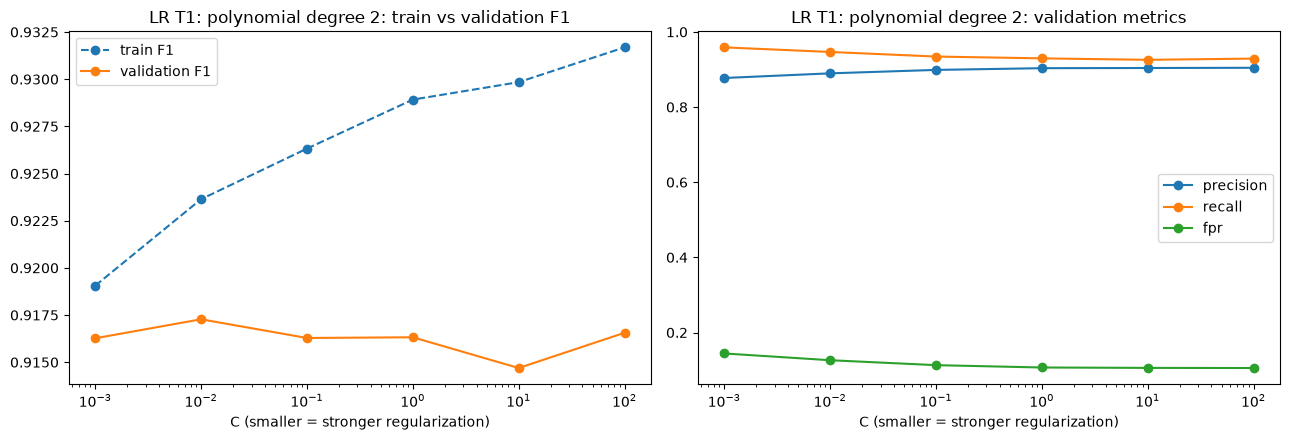

In [5]:
plot_sweep(results, "LR T1: polynomial degree 2", FIGS / "curve_lr_t1_poly2.png")

**Recorded run:** validation F1 peaks at **C=0.01 (0.9174)**. Training F1 rises
from 0.9191 to 0.9317 as regularization weakens, while the gap grows from 0.0028
to 0.0150. This is consistent with overfitting the larger basis; all six settings
converged. Larger C reduces false alarms but also reduces recall. Differences
are small on one validation split, so this is not a significance claim.

**6. The best setting and validation errors**

Keep T1's original rule: select the highest validation F1 among converged fits;
exact ties favor the first (smaller) C. Flagged fits remain in the CSV. An edge
winner suggests considering a wider grid, not a guaranteed improvement.
Validation selects C, so its selected score is not an untouched test estimate.

In [6]:
eligible = results[results["converged"]]
if eligible.empty:
    raise RuntimeError("No converged fit. Results are saved; review optimization before selection.")
best = eligible.loc[eligible["val_f1"].idxmax()]
best_model = fitted[best["value"]]
print(f"Best C={best['value']:g}: val F1={best['val_f1']:.4f}, "
      f"precision={best['val_precision']:.4f}, recall={best['val_recall']:.4f}, "
      f"FPR={best['val_fpr']:.4f}")
if best["value"] in (GRID[0], GRID[-1]):
    print("Best C is at the grid edge: consider extending it.")

Best C=0.01: val F1=0.9173, precision=0.8897, recall=0.9466, FPR=0.1263


The fitted polynomial map below confirms the feature counts and named examples. It reuses the selected pipeline; no additional preprocessing fit is needed.

In [7]:
poly = best_model.named_steps["polynomialfeatures"]
names = poly.get_feature_names_out(best_model.named_steps["columntransformer"].get_feature_names_out())
powers = poly.powers_
term_masks = {
    "Linear": powers.sum(axis=1) == 1,
    "Squares": (powers == 2).any(axis=1),
    "Pairwise products": (powers == 1).sum(axis=1) == 2,
}
pd.DataFrame([
    {"term_type": label, "columns": int(mask.sum()), "examples": list(names[mask][:3])}
    for label, mask in term_masks.items()
])

,term_type,columns,examples
0,Linear,73,"[cat__proto_tcp, cat__proto_udp, cat__proto_unas]"
1,Squares,73,"[cat__proto_tcp^2, cat__proto_udp^2, cat__prot..."
2,Pairwise products,2628,"[cat__proto_tcp cat__proto_udp, cat__proto_tcp..."


The confusion matrix shows true labels in rows and predictions in columns.
Top-right is false alarms; bottom-left is missed attacks. FPR is conditional on
normal traffic, rather than all flows.

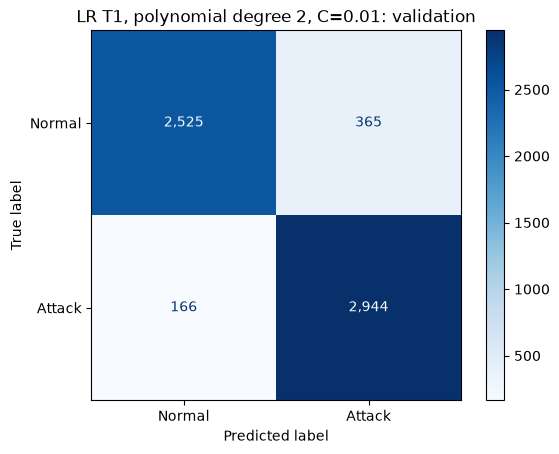

In [8]:
pred_val = best_model.predict(X_val)
ConfusionMatrixDisplay.from_predictions(
    y_val, pred_val, display_labels=["Normal", "Attack"], cmap="Blues", values_format=",",
)
plt.title(f"LR T1, polynomial degree 2, C={best['value']:g}: validation")
plt.savefig(FIGS / "confusion_lr_t1_poly2.png", dpi=150, bbox_inches="tight")
plt.show()

**Which attack types are missed?**

`attack_recall()` uses `attack_cat` only as validation metadata. Compare recall
and absolute misses; small groups such as Worms have uncertain estimates even
at 100% recall.

In [9]:
attack_recall(y_val, pred_val, cat_val)

,rows,caught,missed,recall
type,,,,
Fuzzers,899,758,141,0.843
Analysis,89,83,6,0.933
Shellcode,61,60,1,0.984
Reconnaissance,419,414,5,0.988
Exploits,1105,1094,11,0.990
DoS,212,211,1,0.995
Generic,233,232,1,0.996
Backdoor,85,85,0,1.000
Worms,7,7,0,1.000


**Recorded errors:** 364 false alarms and 166 missed attacks, including 141 Fuzzers. Polynomial interactions do not eliminate the EDA's overlapping or conflicting flows. TTL shortcuts, full-file EDA and repeated feature vectors across splits limit validation independence; these are pre-existing issues. Refresh interpretations after rerunning.

**7. Save the results**

The sweep writes all six settings to `results/lr_t1_poly2.csv`, with `model="LR"`,
`transformation="T1"` and `param="C"`, using the shared metric schema plus `f1_gap`.
The final cell reports that checkpoint without rewriting the CSV. The two plots
use T1-specific filenames; the official test remains reserved for final evaluation.

In [10]:
print("Saved", len(results), "rows to", RESULTS / "lr_t1_poly2.csv")

Saved 6 rows to /Users/victoriajiang/Documents/GitHub/Network-Cyberattack-Detection/verification/lr_t1_cleanup_2026-11-27/runs/cleaned/workspace/results/lr_t1_poly2.csv


In [11]:
_verification_hooks.capture(globals())

VERIFIED six fits, all transformed values by streaming hashes, independent metrics and core plot data; best C=0.01.
